# Shear locking in a Timoshenko cantilever, and two cures

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 7, Section "From Penalty to Lagrange Multiplier", Example "Locking and Its Two Cures".

In dimensionless form, with $s \in (0,1)$, a Timoshenko cantilever under a load $p$ minimizes
$$\mathcal{E}_T(w, \theta) = \int_0^1 \Big( \frac{c}{2\eta}\,(w' - \theta)^2 + \frac{1}{2}\,(\theta')^2 - p\,w \Big)\, ds,
  \qquad w(0) = \theta(0) = 0,$$
where $w$ is the deflection, $\theta$ the rotation of the cross section, $c = \mu/Y$ and $\eta = (\rho/L)^2$ the
square of the slenderness. We take $c = 1$. For a uniform load $p$ the beam is statically determinate:
the shear force is $T = p(1 - s)$, the bending moment $\theta' = p(1-s)^2/2$, and
$$\theta = \frac{p}{6}\big(1 - (1 - s)^3\big), \qquad
  w = p\Big(\frac{s}{6} - \frac{1 - (1-s)^4}{24}\Big) + \eta\, p\Big(s - \frac{s^2}{2}\Big), \qquad
  w(1) = p\Big(\frac{1}{8} + \frac{\eta}{2}\Big),$$
the second part of $w$ being the shear deflection, $w' - \theta = \eta\,T$.

We compare three discretizations:
- **(a)** linear $w$ and $\theta$, shear integral computed exactly (two Gauss points): it **locks**;
- **(b)** the same fields, shear integral computed with **one Gauss point**: this is the mixed method with
  linear $w$, $\theta$ and a piecewise constant shear force;
- **(c)** **quadratic** $w$ and linear $\theta$, exact integration: a richer space for the deflection.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
eta  = 1e-4      # square of the slenderness, (rho/L)^2;  L/t = 20 gives about 2e-4
Ne   = 20        # number of elements
ref  = 1.0       # mesh grading: nodes at (i/Ne)^ref; ref > 1 refines near the clamp
load = "uniform" # "uniform" (p = 1) or "tip" (a force P = 1 at s = 1)
# ---------------------------------------------------------------------------

## 1. The finite elements

On each element the deflection is interpolated by Lagrange polynomials of degree `kw` (1 or 2) and the rotation
by linear ones. The element stiffness is the sum of the bending part, $\int (\theta')^2$, always integrated exactly,
and the shear part, $\frac{1}{\eta}\int (w' - \theta)^2$, integrated with `ng` Gauss points.
The unknowns are ordered as all the nodal deflections first, then all the nodal rotations;
the clamp removes $w(0)$ and $\theta(0)$.

In [2]:
def lagrange(k, x):
    """Lagrange shape functions of degree k on (0,1) and their derivatives at x."""
    if k == 1:
        return np.array([1 - x, x]), np.array([-1.0, 1.0])
    return (np.array([(1 - x) * (1 - 2*x), 4 * x * (1 - x), x * (2*x - 1)]),
            np.array([4*x - 3, 4 - 8*x, 4*x - 1]))

def gauss(n):
    g, wg = np.polynomial.legendre.leggauss(n)
    return (g + 1) / 2, wg / 2

def timoshenko(eta, Ne, kw=1, ng=2, ref=1.0, load="uniform"):
    """Solve the cantilever. Returns the mesh, nodal w (on the vertices), nodal theta, and a function
    giving the shear force (w_h' - theta_h)/eta read at the Gauss points used for the shear."""
    x  = np.linspace(0, 1, Ne + 1)**ref
    h  = np.diff(x)
    nw = kw * Ne + 1
    n  = nw + Ne + 1
    K, F = np.zeros((n, n)), np.zeros(n)
    dofs = lambda e: [kw*e + j for j in range(kw + 1)] + [nw + e, nw + e + 1]
    for e in range(Ne):
        d, he = dofs(e), h[e]
        Ke, Fe = np.zeros((len(d),) * 2), np.zeros(len(d))
        for xi, wt in zip(*gauss(3)):                      # bending and load, exact
            Nw, _ = lagrange(kw, xi); _, dNt = lagrange(1, xi)
            chi = np.concatenate([0 * Nw, dNt / he])
            Ke += wt * he * np.outer(chi, chi)
            if load == "uniform":
                Fe += wt * he * np.concatenate([Nw, [0, 0]])
        for xi, wt in zip(*gauss(ng)):                     # shear, ng Gauss points
            _, dNw = lagrange(kw, xi); Nt, _ = lagrange(1, xi)
            gam = np.concatenate([dNw / he, -Nt])
            Ke += wt * he / eta * np.outer(gam, gam)
        K[np.ix_(d, d)] += Ke; F[d] += Fe
    if load == "tip":
        F[nw - 1] = 1.0
    free = np.setdiff1d(np.arange(n), [0, nw])
    U = np.zeros(n); U[free] = np.linalg.solve(K[np.ix_(free, free)], F[free])
    W, Th = U[:nw], U[nw:]

    def shear(npt=6):
        """Points and values of the shear force (w_h' - theta_h)/eta; with one Gauss point the shear force is
        constant on each element, equal to its value at the midpoint."""
        S, V = [], []
        for e in range(Ne):
            d, he = dofs(e), h[e]
            for xi in np.linspace(0, 1, npt):
                xr = 0.5 if ng == 1 else xi
                _, dNw = lagrange(kw, xr); Nt, _ = lagrange(1, xr)
                S.append(x[e] + xi * he)
                V.append((dNw / he @ U[d[:kw+1]] - Nt @ U[d[kw+1:]]) / eta)
        return np.array(S), np.array(V)
    return x, W[::kw], Th, shear

def exact(s, eta, load="uniform"):
    """Exact w, theta and shear force T of the cantilever."""
    if load == "uniform":
        return (s/6 - (1 - (1 - s)**4)/24 + eta*(s - s**2/2), (1 - (1 - s)**3)/6, 1 - s)
    return (s**2/2 - s**3/6 + eta*s, s - s**2/2, np.ones_like(s))

methods = {"(a) linear, full integration": dict(kw=1, ng=2),
           "(b) linear, one-point shear":  dict(kw=1, ng=1),
           "(c) quadratic w, full":        dict(kw=2, ng=3)}

## 2. Deflection and shear force

The left plot shows the deflection at the nodes, the right one the shear force, recovered from the strain as
$(w_h' - \theta_h)/\eta$. The exact solutions are dashed.

(a) linear, full integration   tip/exact = 0.3246   max nodal error: w 8.4e-02, theta 1.1e-01   L2 error of the shear force: 1.88e+03 %
(b) linear, one-point shear    tip/exact = 1.0000   max nodal error: w 5.2e-05, theta 2.1e-04   L2 error of the shear force: 2.6 %
(c) quadratic w, full          tip/exact = 0.9992   max nodal error: w 1.0e-04, theta 4.0e-12   L2 error of the shear force: 1.97e-09 %


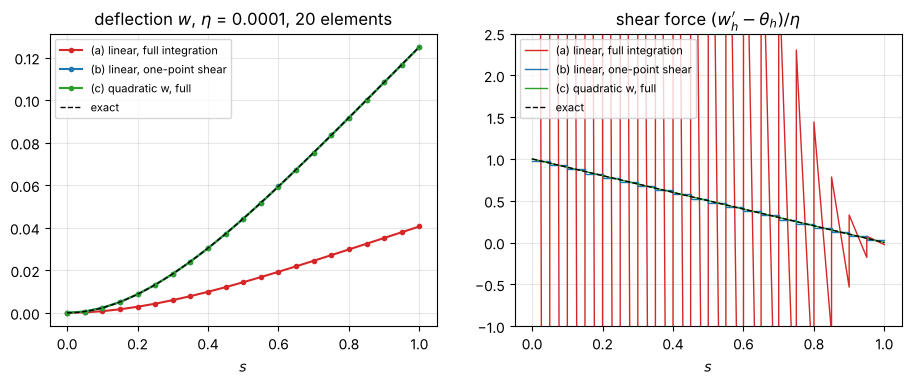

In [3]:
s = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, opt), col in zip(methods.items(), ["C3", "C0", "C2"]):
    x, W, Th, shear = timoshenko(eta, Ne, ref=ref, load=load, **opt)
    ax[0].plot(x, W, "o-", ms=3, color=col, label=name)
    S, V = shear()
    ax[1].plot(S, V, color=col, lw=1, label=name)
    we, te, Te = exact(x, eta, load)
    tip = W[-1] / we[-1]
    Se, _, TS = exact(S, eta, load)
    eT = np.sqrt(np.trapezoid((V - TS)**2, S) / np.trapezoid(TS**2, S))
    print(f"{name:30s} tip/exact = {tip:.4f}   max nodal error: w {np.abs(W - we).max():.1e},"
          f" theta {np.abs(Th - te).max():.1e}   L2 error of the shear force: {100*eT:.3g} %")
we, _, Te = exact(s, eta, load)
ax[0].plot(s, we, "k--", lw=1, label="exact"); ax[1].plot(s, Te, "k--", lw=1, label="exact")
ax[0].set_title(f"deflection $w$, $\\eta$ = {eta:g}, {Ne} elements"); ax[1].set_title("shear force $(w_h' - \\theta_h)/\\eta$")
ax[1].set_ylim(-1, 2.5)
for a in ax: a.set_xlabel("$s$"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.show()

Element (a) is far too stiff, and its shear force, the product of a tiny strain and a huge stiffness $1/\eta$,
swings wildly from one element to the next. Element (b) has the right deflection, and a piecewise constant
shear force equal to the exact one at the midpoints. Element (c) is right as well, and its shear force is exact.

## 3. The locking factor

Section 7.1.2 shows that each linear element with full integration adds a spurious shear strain, and multiplies
the bending stiffness by $1 + c\,h^2/(12\eta)$. In a statically determinate beam the deflection is reduced, roughly,
by the same factor. We check it on the tip deflection, as a function of $\eta$.

tip deflection / exact (uniform load)
                                Ne   eta = 0.01     eta = 0.0001   eta = 1e-06    
(a) linear, full integration     4   0.6707         0.0192         0.0002         
(a) linear, full integration    20   0.9804         0.3246         0.0048         
(a) linear, full integration   100   0.9992         0.9231         0.1071         
(b) linear, one-point shear      4   1.0000         1.0000         1.0000         
(b) linear, one-point shear     20   1.0000         1.0000         1.0000         
(b) linear, one-point shear    100   1.0000         1.0000         1.0000         
(c) quadratic w, full            4   0.9800         0.9792         0.9792         
(c) quadratic w, full           20   0.9992         0.9992         0.9992         
(c) quadratic w, full          100   1.0000         1.0000         1.0000         


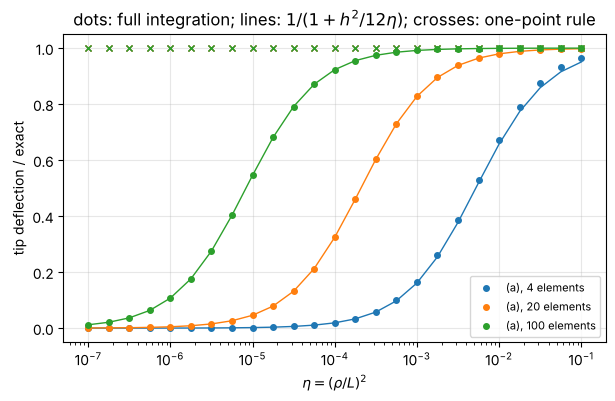

In [4]:
etas = np.logspace(-7, -1, 25)
fig, ax = plt.subplots(figsize=(7, 4))
for N, col in zip([4, 20, 100], ["C0", "C1", "C2"]):
    ratio = [timoshenko(et, N, kw=1, ng=2)[1][-1] / exact(1.0, et)[0] for et in etas]
    ax.semilogx(etas, ratio, "o", ms=4, color=col, label=f"(a), {N} elements")
    ax.semilogx(etas, 1 / (1 + (1/N)**2 / (12 * etas)), "-", color=col, lw=1)
    ratio_b = [timoshenko(et, N, kw=1, ng=1)[1][-1] / exact(1.0, et)[0] for et in etas]
    ax.semilogx(etas, ratio_b, "x", ms=4, color=col)
ax.set_xlabel("$\\eta = (\\rho/L)^2$"); ax.set_ylabel("tip deflection / exact")
ax.set_title("dots: full integration; lines: $1/(1 + h^2/12\\eta)$; crosses: one-point rule")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

print("tip deflection / exact (uniform load)")
print(f"{'':30s}{'Ne':>4s}   " + "".join(f"eta = {et:<9g}" for et in [1e-2, 1e-4, 1e-6]))
for name, opt in methods.items():
    for N in [4, 20, 100]:
        print(f"{name:30s}{N:4d}   " + "".join(f"{timoshenko(et, N, **opt)[1][-1] / exact(1.0, et)[0]:<15.4f}"
                                          for et in [1e-2, 1e-4, 1e-6]))

## 4. Why: the size of the discrete constraint space

As $\eta \to 0$ every method tends to the minimizer over $\mathcal{G}_h$, the discrete fields with zero
shear energy. Its dimension is the number of zero eigenvalues of the shear part of the stiffness matrix
(with the clamp). Element (a) has none: $\mathcal{G}_h = \{0\}$, the beam cannot bend without shear.
Elements (b) and (c) have one per element: every continuous piecewise linear rotation, with a deflection
whose slope matches it (on average in (b), exactly in (c)).

In [5]:
def shear_kernel(Ne, kw, ng):
    h = 1 / Ne; nw = kw * Ne + 1; n = nw + Ne + 1
    Ks = np.zeros((n, n))
    for e in range(Ne):
        d = [kw*e + j for j in range(kw + 1)] + [nw + e, nw + e + 1]
        for xi, wt in zip(*gauss(ng)):
            _, dNw = lagrange(kw, xi); Nt, _ = lagrange(1, xi)
            gam = np.concatenate([dNw / h, -Nt]); Ks[np.ix_(d, d)] += wt * h * np.outer(gam, gam)
    free = np.setdiff1d(np.arange(n), [0, nw])
    ev = np.linalg.eigvalsh(Ks[np.ix_(free, free)])
    return np.sum(ev < 1e-10 * ev.max()), len(free)

for name, opt in methods.items():
    print(name, " ".join(f"| {Ne} el.: dim G_h = {g} of {n} unknowns" for Ne in [4, 20]
                         for g, n in [shear_kernel(Ne, opt["kw"], opt["ng"])]))

(a) linear, full integration | 4 el.: dim G_h = 0 of 8 unknowns | 20 el.: dim G_h = 0 of 40 unknowns
(b) linear, one-point shear | 4 el.: dim G_h = 4 of 8 unknowns | 20 el.: dim G_h = 20 of 40 unknowns
(c) quadratic w, full | 4 el.: dim G_h = 4 of 12 unknowns | 20 el.: dim G_h = 20 of 60 unknowns


## Things to try

1. **Thicker and thinner beams.** Set `eta = 1e-2` (a stocky beam, $L/t \approx 3$): locking is mild. Then
   `eta = 1e-6`: element (a) gives half a percent of the deflection with 20 elements. How many elements does it
   need for an error of 1%? Compare with the rule of thumb "elements shorter than the thickness".
2. **A tip force.** Set `load = "tip"`. Element (b) is still free of locking, but its tip deflection is no longer
   exact: with the uniform load the exactness was a gift of the load, not a property of the element.
3. **A graded mesh.** With `ref = 2` the elements near the clamp are shorter. Does grading help element (a)?
   (The locking factor depends on the length of each element.)
4. **Round-off.** Push `eta` down to `1e-10` and watch the nodal errors of elements (b) and (c): the stiffness
   matrix contains $1/\eta$, and its condition number grows accordingly. The mixed formulation, with $\eta$ in
   front of the complementary energy, does not suffer from this.
5. **Another mixed formulation.** In the course exercise from which this notebook is drawn, the shear force $T$
   and the bending moment $M$ are independent unknowns, continuous and piecewise linear like $w$ and $\theta$,
   and the solution is a stationary point of
   $\int \big(-\tfrac{\eta}{2c} T^2 - \tfrac{1}{2} M^2 - T' w - (M' + T)\,\theta - p\, w\big)$,
   with $T(1) = M(1) = 0$ imposed and the clamp left natural: the derivatives have moved from the displacements to
   the forces, as in the third mixed form of the Euler beam (Section 7.2). Check that the stationarity conditions
   are the equations of the beam, write the matrices and solve: is the computed shear force exact?